**INSTALL DEPENDENCIES**

APPENDIX SECTION

In [ ]:
!pip install numpy pandas scipy shapely plotly fiona scikit-learn geopandas mapclassify

In [ ]:
#load essential libraries
import numpy as np
import pandas as pd
import scipy as sp
import plotly as pl
import fiona as fi
import mapclassify
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely import contains_xy
from matplotlib import pyplot as plt
from scipy.spatial import cKDTree
from sklearn.metrics import mean_squared_error, mean_absolute_error


load data and ensure consistent rcs

In [ ]:
gpkg_path = "/content/Datasets.gpkg"
# Read housing price points
houses = gpd.read_file(gpkg_path, layer="houselocationandprices")

# Read Nairobi boundary
boundary = gpd.read_file(gpkg_path, layer="Nairobi")

print(houses.crs)
print(boundary.crs)



EPSG:21037
EPSG:21037


**Inverse Distance Weighting**

---



## **Inspect sample of housing prices**


In [ ]:
print("Available columns:", list(houses.columns))
houses.head()


Available columns: ['number', 'Size', 'price', 'lat', 'lon', 'Town', 'geometry']


,number,Size,price,lat,lon,Town,geometry
0,5,5,72000000,-1.274068,36.776227,Lavington,POINT (252450.969 9859369.452)
1,6,5,46000000,-1.266670,36.800000,"grevallia, Spring Valley, Westlands",POINT (255096.956 9860190.009)
2,7,5,85000000,-1.274068,36.776227,Lavington,POINT (252450.969 9859369.452)
3,8,5,50000000,-1.276734,36.787901,Kileleshwa,POINT (253750.928 9859075.673)
4,9,5,75000000,-1.274068,36.776227,Lavington,POINT (252450.969 9859369.452)


Plot to verify dataset extent

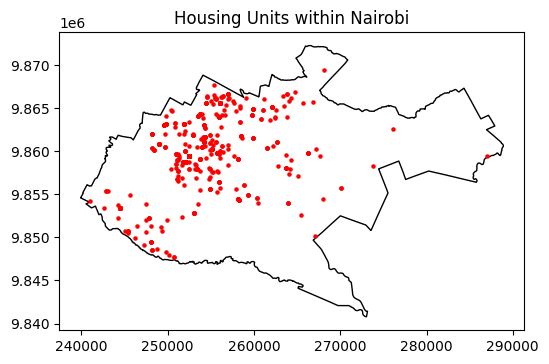

In [ ]:
ax = boundary.plot(figsize=(6,6), edgecolor="black", facecolor="none")
houses.plot(ax=ax, color="red", markersize=5)
plt.title("Housing Units within Nairobi")
plt.show()


Compute the mesh grid

In [ ]:

xmin, ymin, xmax, ymax = boundary.total_bounds

nx, ny = 300, 300   # increase for finer resolution, but slower
xi = np.linspace(xmin, xmax, nx)
yi = np.linspace(ymin, ymax, ny)
xi, yi = np.meshgrid(xi, yi)

print(" Meshgrid shape:", xi.shape)



 Meshgrid shape: (300, 300)


Plot the meshgrid

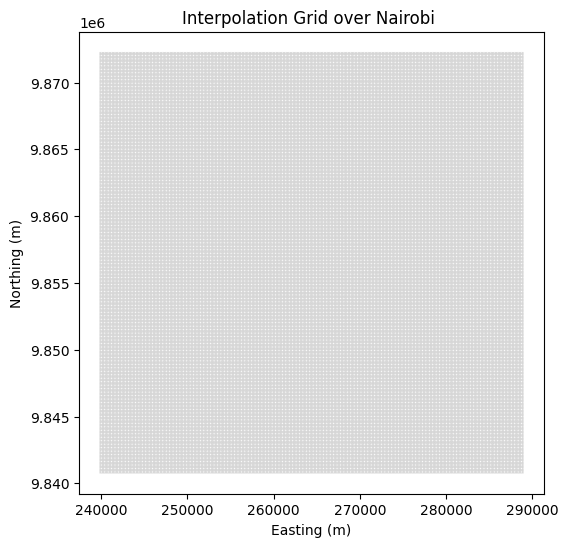

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(xi, yi, s=0.009, facecolors="none", edgecolors="grey")
plt.title("Interpolation Grid over Nairobi ")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.show()


Plot meshgrid against boundary and housing prices to ensure extent

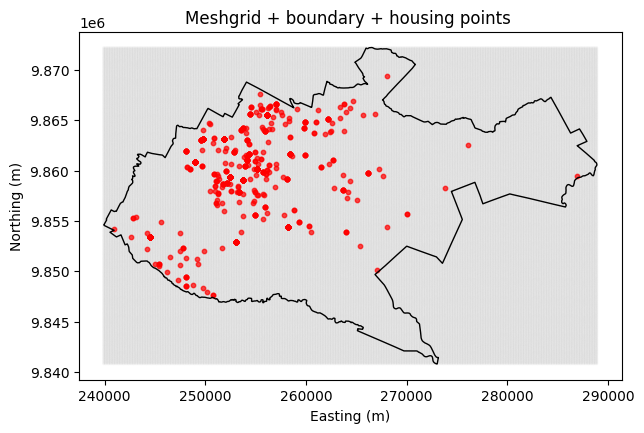

In [ ]:
plt.figure(figsize=(7,7))
plt.scatter(xi, yi, s=1, facecolors="none", edgecolors="grey", alpha=0.07, label="meshgrid")
boundary.boundary.plot(ax=plt.gca(), color="black", linewidth=1, label="boundary")
houses.plot(ax=plt.gca(), color="red", markersize=10, alpha=0.7, label="houses")
plt.title("Meshgrid + boundary + housing points ")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.show()


Compute distance matrix

In [ ]:
def idw_ckdtree_from_meshgrid(houses_gdf, value_col, xi, yi, k=12, beta=2, eps=1e-12):
    """
    IDW interpolation using cKDTree (k nearest neighbors) on a pre-built meshgrid.

    houses_gdf : GeoDataFrame with Point geometries (UTM meters)
    value_col  : column name for observed values (e.g. 'price')
    xi, yi     : 2D meshgrid arrays
    k          : number of nearest neighbors
    beta       : IDW power parameter
    """
    # Observed coords
    x_obs = houses_gdf.geometry.x.values
    y_obs = houses_gdf.geometry.y.values

    # Observed values
    if value_col not in houses_gdf.columns:
        raise KeyError(f"'{value_col}' not found. Available: {list(houses_gdf.columns)}")
    z_obs = houses_gdf[value_col].astype(float).values

    # Build KDTree
    obs_xy = np.column_stack([x_obs, y_obs])
    tree = cKDTree(obs_xy)

    # Flatten meshgrid to query points
    interp_xy = np.column_stack([xi.ravel(), yi.ravel()])

    # Ensure valid k
    k_eff = min(k, len(z_obs))

    # Query k nearest neighbors
    distances, indices = tree.query(interp_xy, k=k_eff)

    # Ensure 2D shapes if k_eff=1
    if k_eff == 1:
        distances = distances[:, None]
        indices = indices[:, None]

    # Compute weights: w = d^(-beta)
    distances = np.maximum(distances, eps)
    weights = distances ** (-beta)
    weights /= weights.sum(axis=1, keepdims=True)

    # Weighted prediction
    z_neigh = z_obs[indices]
    zi = np.sum(weights * z_neigh, axis=1)

    return zi.reshape(xi.shape)


In [ ]:
zi_grid = idw_ckdtree_from_meshgrid(
    houses_gdf=houses,
    value_col="price",
    xi=xi,
    yi=yi,
    k=12,
    beta=2
)

print("IDW interpolation done. Output grid shape:", zi_grid.shape)



IDW interpolation done. Output grid shape: (300, 300)


Plot Outputs

Mask outside Nairobi

In [ ]:
poly = boundary.geometry.iloc[0]

inside = contains_xy(poly, xi, yi)
zi_masked = np.where(inside, zi_grid, np.nan)

print("Total grid cells:", xi.size)
print("Inside Nairobi:", int(np.count_nonzero(inside)))
print("Outside Nairobi:", int(np.count_nonzero(~inside)))

Total grid cells: 90000
Inside Nairobi: 41357
Outside Nairobi: 48643


plot interpolated surface

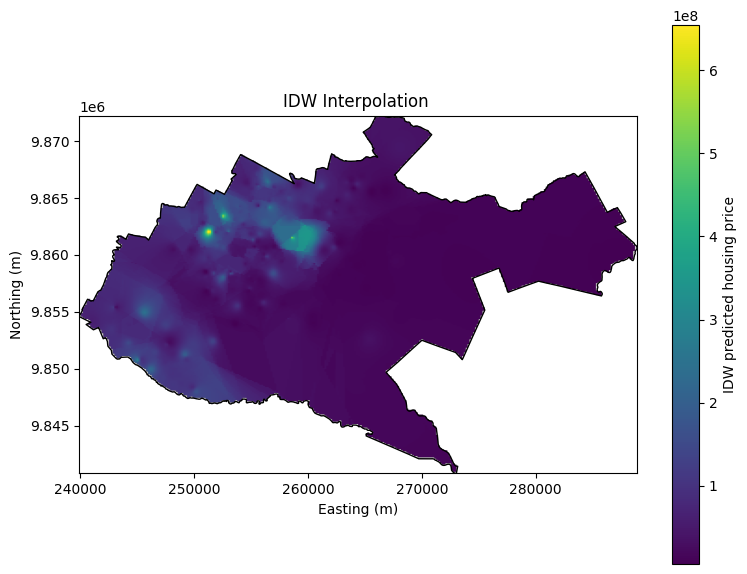

In [ ]:
plt.figure(figsize=(9,7))
plt.imshow(
    zi_masked,
    origin="lower",
    extent=[xmin, xmax, ymin, ymax]
)
plt.colorbar(label="IDW predicted housing price")
boundary.boundary.plot(ax=plt.gca(), color="black", linewidth=1)
plt.title("IDW Interpolation ")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.show()


Validation :LOOCV

In [ ]:

def idw_predict_ckdtree(train_xy, train_z, query_xy, k=12, beta=2, eps=1e-12):
    """
    Predict values at query_xy using IDW with cKDTree on train points.
    Uses k-nearest neighbors.
    """
    tree = cKDTree(train_xy)

    k_eff = min(k, len(train_z))
    distances, indices = tree.query(query_xy, k=k_eff)

    # ensure 2D
    if k_eff == 1:
        distances = distances[:, None]
        indices = indices[:, None]

    distances = np.maximum(distances, eps)

    weights = distances ** (-beta)
    weights /= weights.sum(axis=1, keepdims=True)

    z_neigh = train_z[indices]
    preds = np.sum(weights * z_neigh, axis=1)
    return preds


def idw_loocv_ckdtree(obs_xy, obs_z, k=12, beta=2):
    """
    Leave-One-Out Cross Validation for IDW (cKDTree).
    Returns predictions, residuals, RMSE, MAE.
    """
    n = len(obs_z)
    preds = np.empty(n, dtype=float)

    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False

        train_xy = obs_xy[mask]
        train_z  = obs_z[mask]

        # Predict the left-out point using remaining points
        preds[i] = idw_predict_ckdtree(
            train_xy, train_z,
            obs_xy[i:i+1],
            k=k,
            beta=beta
        )[0]

    residuals = obs_z - preds
    rmse = np.sqrt(mean_squared_error(obs_z, preds))
    mae  = mean_absolute_error(obs_z, preds)

    return preds, residuals, rmse, mae


In [ ]:
# Observed coords + values (from your GeoDataFrame)
obs_xy = np.column_stack([houses.geometry.x.values, houses.geometry.y.values])
obs_z  = houses["price"].astype(float).values

# Use the SAME parameters as your IDW surface
k = 12
beta = 2

preds, residuals, rmse, mae = idw_loocv_ckdtree(obs_xy, obs_z, k=k, beta=beta)

print(f"IDW LOOCV RMSE: {rmse:.2f}")
print(f"IDW LOOCV MAE : {mae:.2f}")


IDW LOOCV RMSE: 65227527.76
IDW LOOCV MAE : 38091322.72


In [ ]:
houses["idw_loocv_pred"] = preds
houses["idw_loocv_resid"] = residuals
houses["idw_loocv_abs_resid"] = np.abs(residuals)

houses[["price", "idw_loocv_pred", "idw_loocv_resid"]].head()


,price,idw_loocv_pred,idw_loocv_resid
0,72000000,8.058333e+07,-8.583333e+06
1,46000000,7.979167e+07,-3.379167e+07
2,85000000,7.833333e+07,6.666667e+06
3,50000000,9.325000e+07,-4.325000e+07
4,75000000,7.833333e+07,-3.333333e+06


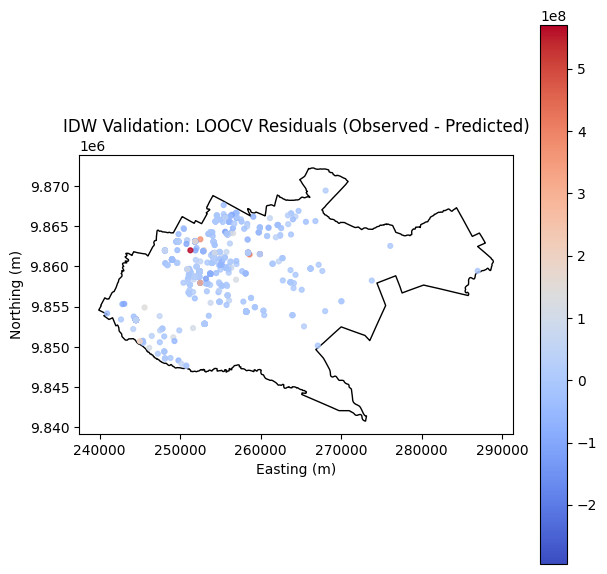

In [ ]:
ax = boundary.plot(figsize=(7,7), edgecolor="black", facecolor="none")
houses.plot(
    ax=ax,
    column="idw_loocv_resid",
    cmap="coolwarm",
    legend=True,
    markersize=12,
    alpha=0.8
)
plt.title("IDW Validation: LOOCV Residuals (Observed - Predicted)")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.show()


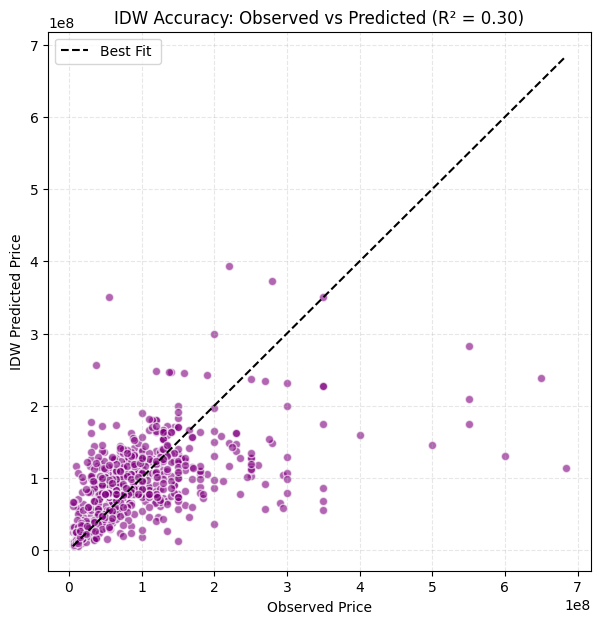

In [ ]:
from sklearn.metrics import r2_score


observed = houses["price"]
predicted = houses["idw_loocv_pred"]

# Calculate R2 for the plot title
r2 = r2_score(observed, predicted)

plt.figure(figsize=(7,7))
plt.scatter(observed, predicted, alpha=0.6, color="purple", edgecolors="w")

# Add the line of best fit
min_val = min(observed.min(), predicted.min())
max_val = max(observed.max(), predicted.max())
plt.plot([min_val, max_val], [min_val, max_val], "k--", label="Best Fit ")

plt.xlabel("Observed Price")
plt.ylabel("IDW Predicted Price")
plt.title(f"IDW Accuracy: Observed vs Predicted (R² = {r2:.2f})")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

# **GWR**

---



In [ ]:

base_layer   = "sampledpop"         # houses + population
roads_layer  = "distancetoroads"     # distance to hub output for roads
parks_layer  = "distancetoparks"    # distance to hub output for parks

sampledpop = gpd.read_file(gpkg_path, layer=base_layer)
dist_roads = gpd.read_file(gpkg_path, layer=roads_layer)
dist_parks = gpd.read_file(gpkg_path, layer=parks_layer)

print("sampledpop:", sampledpop.shape)
print("dist_roads:", dist_roads.shape)
print("dist_parks:", dist_parks.shape)

print("CRS:", sampledpop.crs, dist_roads.crs, dist_parks.crs)
if not (sampledpop.crs == dist_roads.crs == dist_parks.crs):
    raise ValueError("CRS mismatch. All layers must be in the same CRS.")


sampledpop: (849, 8)
dist_roads: (849, 9)
dist_parks: (849, 9)
CRS: EPSG:21037 EPSG:21037 EPSG:21037


In [ ]:
print(sampledpop.columns.tolist())
print(dist_roads.columns.tolist())
print(dist_parks.columns.tolist())

['number', 'Size', 'price', 'lat', 'lon', 'Town', 'population1', 'geometry']
['number', 'Size', 'price', 'lat', 'lon', 'Town', 'HubName', 'HubDist', 'geometry']
['number', 'Size', 'price', 'lat', 'lon', 'Town', 'HubName', 'HubDist', 'geometry']


In [ ]:
dist_roads = dist_roads.rename(columns={
    "HubName": "roadname",
    "HubDist": "roaddistance"
})

dist_parks = dist_parks.rename(columns={
    "HubName": "parkname",
    "HubDist": "parkdistance"
})
sampledpop = sampledpop.rename(columns={
    "population1":"population"
})


print("Roads columns:", dist_roads.columns.tolist())
print("Parks columns:", dist_parks.columns.tolist())
print("Sampledpop columns:", sampledpop.columns.tolist())


Roads columns: ['number', 'Size', 'price', 'lat', 'lon', 'Town', 'roadname', 'roaddistance', 'geometry']
Parks columns: ['number', 'Size', 'price', 'lat', 'lon', 'Town', 'parkname', 'parkdistance', 'geometry']
Sampledpop columns: ['number', 'Size', 'price', 'lat', 'lon', 'Town', 'population', 'geometry']


In [ ]:
for name, df in [("sampledpop", sampledpop), ("dist_roads", dist_roads), ("dist_parks", dist_parks)]:
    if "number" not in df.columns:
        raise KeyError(f"'number' column missing in {name}.")

base = sampledpop[["number", "price", "population", "Size", "Town", "geometry"]].copy()
roads_small = dist_roads[["number", "roadname", "roaddistance"]].copy()
parks_small = dist_parks[["number", "parkname", "parkdistance"]].copy()

gwr_feature_space = base.merge(roads_small, on="number", how="left") \
                .merge(parks_small, on="number", how="left")

print(" gwr_ready shape:", gwr_feature_space.shape)
gwr_feature_space.head(10)



 gwr_ready shape: (849, 10)


,number,price,population,Size,Town,geometry,roadname,roaddistance,parkname,parkdistance
0,5,72000000,3574.764160,5,Lavington,POINT (252450.969 9859369.452),None,41.198547,None,2098.649737
1,6,46000000,4859.701172,5,"grevallia, Spring Valley, Westlands",POINT (255096.956 9860190.009),Nairobi Expressway,298.459032,Westlands Botanical Garden,1062.800331
2,7,85000000,3574.764160,5,Lavington,POINT (252450.969 9859369.452),None,41.198547,None,2098.649737
3,8,50000000,4871.504883,5,Kileleshwa,POINT (253750.928 9859075.673),Kandara Road,63.944727,None,1948.254848
4,9,75000000,3574.764160,5,Lavington,POINT (252450.969 9859369.452),None,41.198547,None,2098.649737
5,11,140000000,2971.861084,4,Muthaiga,POINT (258447.12 9861694.84),Muthaiga Road,318.492007,City Park,1172.993151
6,14,50000000,3574.764160,5,Lavington,POINT (252450.969 9859369.452),None,41.198547,None,2098.649737
7,15,55000000,3574.764160,5,Lavington,POINT (252450.969 9859369.452),None,41.198547,None,2098.649737
8,16,85000000,23279.433594,4,"Loresho, Westlands",POINT (249003.167 9860833.769),None,147.910976,None,3188.065740
9,20,15000000,20508.535156,3,Ngumo Estate,POINT (254896.529 9855604.598),None,10.570226,Uhuru Gardens,1967.998466


In [ ]:
missing = gwr_feature_space[["population", "roaddistance", "parkdistance"]].isna().sum()
print("Missing values:\n", missing)

if missing.any():
    print("\n Missing values found. Possible causes:")
    print(" - 'number' values differ between layers")
    print(" - one of the distance layers is missing some points")


Missing values:
 population      0
roaddistance    0
parkdistance    0
dtype: int64


In [ ]:
out_layer = "houses_gwr_feature_space"
gwr_feature_space.to_file(gpkg_path, layer=out_layer, driver="GPKG")
print(" Saved merged layer:", out_layer)


 Saved merged layer: houses_gwr_feature_space


In [ ]:
print("min price:", gwr_feature_space["price"].min())
print("count price <= 0:", (gwr_feature_space["price"] <= 0).sum())

for c in ["population", "roaddistance", "parkdistance"]:
    s = gwr_feature_space[c]
    print(c, "min:", s.min(), "max:", s.max(), "unique:", s.nunique(), "n_null:", s.isna().sum())

coords_df = gwr_feature_space.copy()
coords_df["x"] = coords_df.geometry.x
coords_df["y"] = coords_df.geometry.y

dup = coords_df.duplicated(subset=["x","y"]).sum()
print("Duplicate coordinate rows:", dup)


min price: 5500000
count price <= 0: 0
population min: 279.411376953125 max: 71844.9453125 unique: 122 n_null: 0
roaddistance min: 0.042315130840308204 max: 2492.6529909433616 unique: 217 n_null: 0
parkdistance min: 12.288562015079355 max: 14237.438829235904 unique: 217 n_null: 0
Duplicate coordinate rows: 632


In [ ]:
import pandas as pd

tmp = gwr_feature_space[["population","roaddistance","parkdistance"]].copy()
print(tmp.corr())


              population  roaddistance  parkdistance
population      1.000000     -0.122818      0.181782
roaddistance   -0.122818      1.000000      0.011469
parkdistance    0.181782      0.011469      1.000000


In [ ]:
import geopandas as gpd
from shapely.geometry import Point

g = gwr_feature_space.copy()

# Extract coordinates
g["x"] = g.geometry.x
g["y"] = g.geometry.y

# Aggregate numeric variables at identical locations
g_collapsed = g.groupby(["x", "y"], as_index=False).agg({
    "price": "mean",
    "population": "mean",
    "roaddistance": "mean",
    "parkdistance": "mean"
})

# Rebuild geometry
g_collapsed = gpd.GeoDataFrame(
    g_collapsed,
    geometry=[Point(xy) for xy in zip(g_collapsed["x"], g_collapsed["y"])],
    crs=gwr_feature_space.crs
)

print("Original rows:", gwr_feature_space.shape[0])
print("After collapsing duplicates:", g_collapsed.shape[0])


Original rows: 849
After collapsing duplicates: 217


In [ ]:
gwr_feature_space = g_collapsed


In [ ]:
import numpy as np
from mgwr.sel_bw import Sel_BW
from mgwr.gwr import GWR

# Coordinates
coords = np.column_stack([
    gwr_feature_space.geometry.x.values,
    gwr_feature_space.geometry.y.values
])

# Dependent variable (log price)
y = np.log(gwr_feature_space["price"].values).reshape((-1, 1))

# Predictors (NO intercept column here)
X = gwr_feature_space[["population", "roaddistance", "parkdistance"]].values

# Scale predictors (recommended for stability)
X = (X - X.mean(axis=0)) / X.std(axis=0)   # z-score standardization


In [ ]:
bw_selector = Sel_BW(
    coords, y, X,
    fixed=False,
    kernel="bisquare",
    constant=True
)

bw = bw_selector.search(criterion="AICc")
print(" Optimal bandwidth:", bw)


 Optimal bandwidth: 50.0


In [ ]:
from mgwr.gwr import GWR

gwr_model = GWR(
    coords,
    y,
    X,
    bw=bw,
    fixed=False,
    kernel="bisquare",
    constant=True
)

gwr_results = gwr_model.fit()

print(gwr_results.summary())


Model type                                                         Gaussian
Number of observations:                                                 217
Number of covariates:                                                     4

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            183.413
Log-likelihood:                                                    -289.665
AIC:                                                                587.330
AICc:                                                               589.614
BIC:                                                               -962.505
R2:                                                                   0.104
Adj. R2:                                                              0.091

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [ ]:
gwr_feature_space["b_intercept"]     = gwr_results.params[:, 0]
gwr_feature_space["b_population"]   = gwr_results.params[:, 1]
gwr_feature_space["b_roaddistance"] = gwr_results.params[:, 2]
gwr_feature_space["b_parkdistance"] = gwr_results.params[:, 3]

gwr_feature_space["local_R2"]        = gwr_results.localR2
gwr_feature_space["gwr_residual"]    = gwr_results.resid_response.flatten()


Plot coefficients

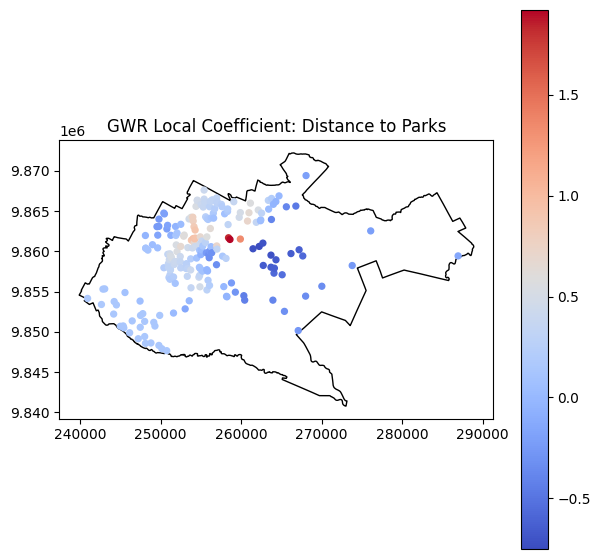

In [ ]:
ax = boundary.plot(figsize=(7,7), edgecolor="black", facecolor="none")
gwr_feature_space.plot(
    ax=ax,
    column="b_parkdistance",
    cmap="coolwarm",
    legend=True,
    markersize=18
)
plt.title("GWR Local Coefficient: Distance to Parks")
plt.show()


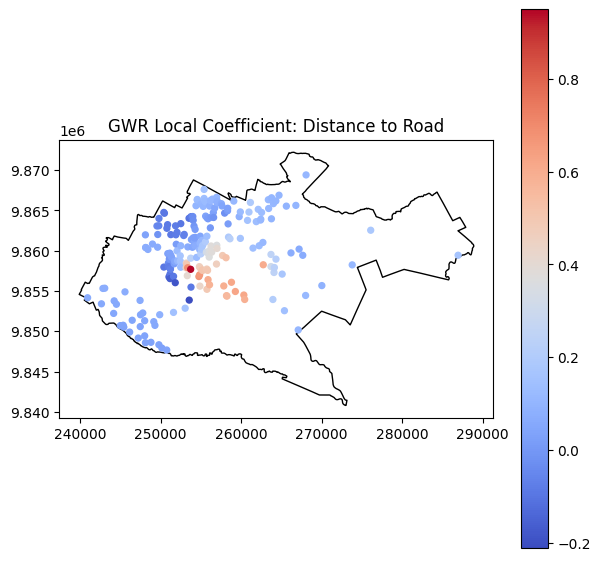

In [ ]:
ax = boundary.plot(figsize=(7,7), edgecolor="black", facecolor="none")
gwr_feature_space.plot(
    ax=ax,
    column="b_roaddistance",
    cmap="coolwarm",
    legend=True,
    markersize=18
)
plt.title("GWR Local Coefficient: Distance to Road")
plt.show()

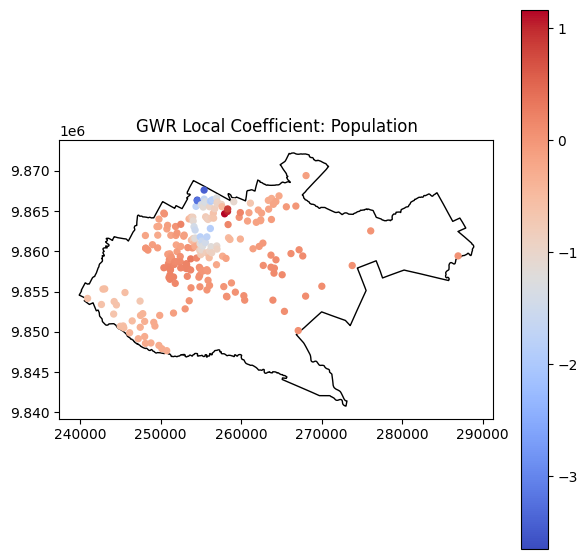

In [ ]:
ax = boundary.plot(figsize=(7,7), edgecolor="black", facecolor="none")
gwr_feature_space.plot(
    ax=ax,
    column="b_population",
    cmap="coolwarm",
    legend=True,
    markersize=18
)
plt.title("GWR Local Coefficient: Population")
plt.show()

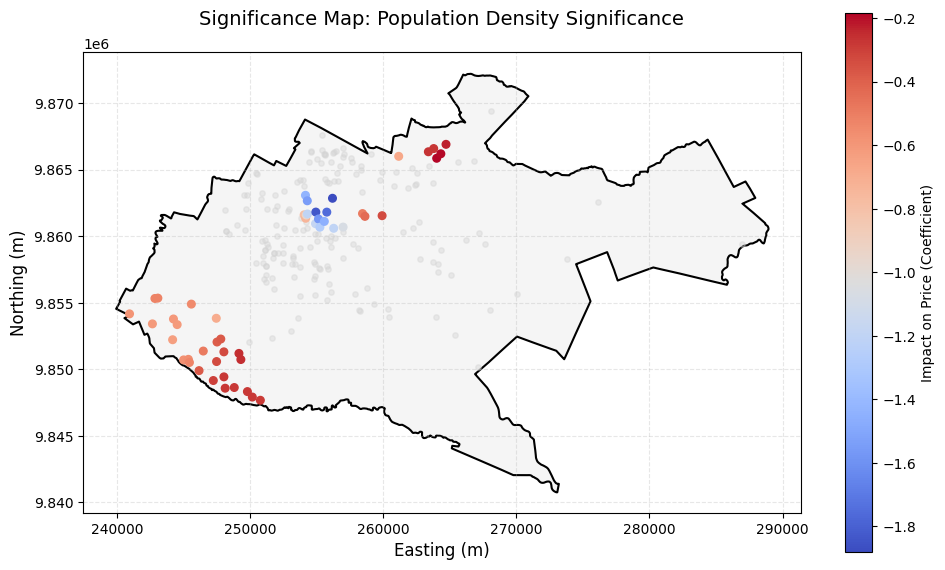

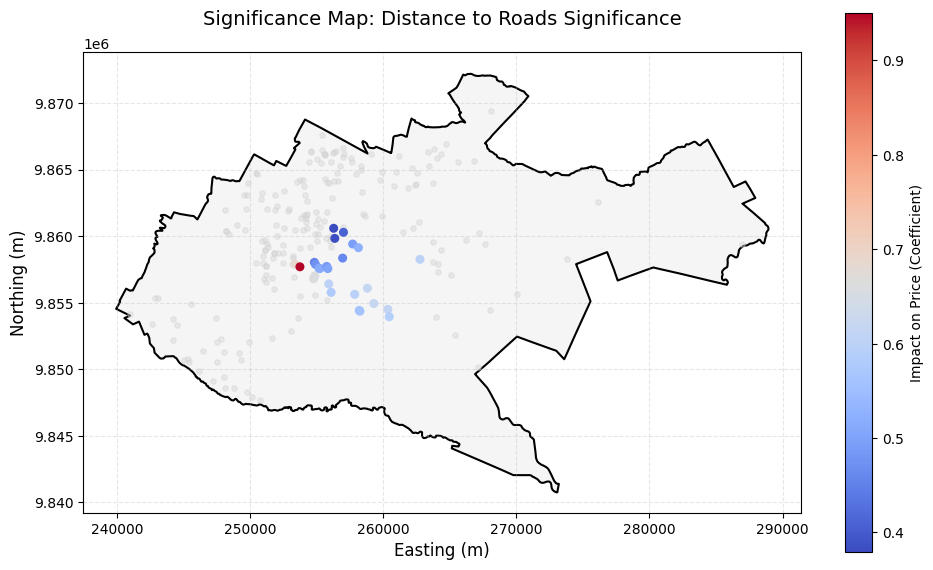

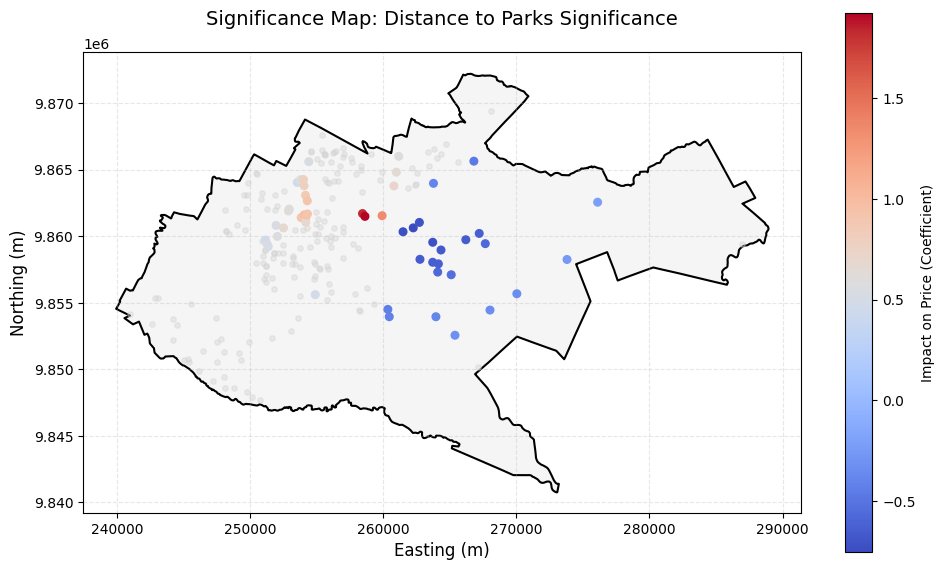

--- Summary of Significant Locations ---
Population: Significant in 51 / 217 locations (23.5%)
Roads: Significant in 26 / 217 locations (12.0%)
Parks: Significant in 51 / 217 locations (23.5%)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==========================================
# 1. CALCULATE T-VALUES AND SIGNIFICANCE
# ==========================================

# Extract Standard Errors (SE) from results
# Index mapping based on your input: 0=Intercept, 1=Population, 2=Roads, 3=Parks
se_population = gwr_results.bse[:, 1]
se_road       = gwr_results.bse[:, 2]
se_park       = gwr_results.bse[:, 3]

# Calculate t-values (Coefficient / Standard Error)
gwr_feature_space["t_population"] = gwr_feature_space["b_population"] / se_population
gwr_feature_space["t_road"]       = gwr_feature_space["b_roaddistance"] / se_road
gwr_feature_space["t_park"]       = gwr_feature_space["b_parkdistance"] / se_park

# Define Significance Threshold (1.96 = 95% Confidence)
z_critical = 1.96

# ==========================================
# 2. PLOTTING FUNCTION
# ==========================================

def plot_significance(variable_name, t_col, coef_col, title):
    """
    Plots a map masking insignificant areas in grey.
    """
    fig, ax = plt.subplots(figsize=(10, 8))

    # A. Plot the Boundary (Basemap)
    boundary.plot(ax=ax, edgecolor="black", facecolor="whitesmoke", linewidth=1.5, zorder=1)

    # B. Create Masks
    # Significant: t > 1.96 OR t < -1.96
    is_sig = gwr_feature_space[t_col].abs() > z_critical

    sig_points = gwr_feature_space[is_sig]
    insig_points = gwr_feature_space[~is_sig]

    # C. Plot INSIGNIFICANT points (Grey)
    if not insig_points.empty:
        insig_points.plot(
            ax=ax,
            color="lightgrey",
            markersize=15,
            alpha=0.4,
            zorder=2,
            label="Insignificant (p > 0.05)"
        )

    # D. Plot SIGNIFICANT points (Colored by Coefficient)
    if not sig_points.empty:
        plot = sig_points.plot(
            ax=ax,
            column=coef_col,
            cmap="coolwarm",      # Red = Positive, Blue = Negative
            markersize=30,
            alpha=1.0,
            legend=True,
            zorder=3,
            legend_kwds={
                'label': f"Impact on Price (Coefficient)",
                'orientation': "vertical",
                'shrink': 0.7
            }
        )

    # E. Formatting Labels and Legend
    ax.set_title(f"Significance Map: {title}", fontsize=14, pad=20)
    ax.set_xlabel("Easting (m)", fontsize=12)
    ax.set_ylabel("Northing (m)", fontsize=12)

    # Manually add the "Insignificant" grey dot to the legend
    grey_patch = mpatches.Patch(color='lightgrey', label='Insignificant (t < 1.96)')


    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. GENERATE THE MAPS
# ==========================================

# Map 1: Population Density
plot_significance(
    variable_name="Population",
    t_col="t_population",
    coef_col="b_population",
    title="Population Density Significance"
)

# Map 2: Distance to Roads
plot_significance(
    variable_name="Roads",
    t_col="t_road",
    coef_col="b_roaddistance",
    title="Distance to Roads Significance"
)

# Map 3: Distance to Parks
plot_significance(
    variable_name="Parks",
    t_col="t_park",
    coef_col="b_parkdistance",
    title="Distance to Parks Significance"
)

# Print Summary Stats for the Report
print("--- Summary of Significant Locations ---")
for name, col in [("Population", "t_population"), ("Roads", "t_road"), ("Parks", "t_park")]:
    sig_count = (gwr_feature_space[col].abs() > 1.96).sum()
    total = len(gwr_feature_space)
    print(f"{name}: Significant in {sig_count} / {total} locations ({sig_count/total:.1%})")

**Validation**

---



Check for autocorrelation

In [ ]:
from esda.moran import Moran
from libpysal.weights import Queen, KNN

# 1. Create spatial weights matrix (W)
w = KNN.from_dataframe(gwr_feature_space, k=8)
w.transform = 'r' # Row-standardize

# 2. Calculate Moran's I on the GWR residuals
mi = Moran(gwr_feature_space["gwr_residual"], w)

print(f"Moran's I of Residuals: {mi.I: .3f}")
print(f"P-value: {mi.p_sim: .5f}")

# Interpretation
if mi.p_sim < 0.05:
    print("WARNING: Residuals are significantly clustered. Model may be misspecified.")
else:
    print("SUCCESS: Residuals appear random (spatial stationarity achieved).")

Moran's I of Residuals: -0.003
P-value:  0.46000
SUCCESS: Residuals appear random (spatial stationarity achieved).


Map local R squared

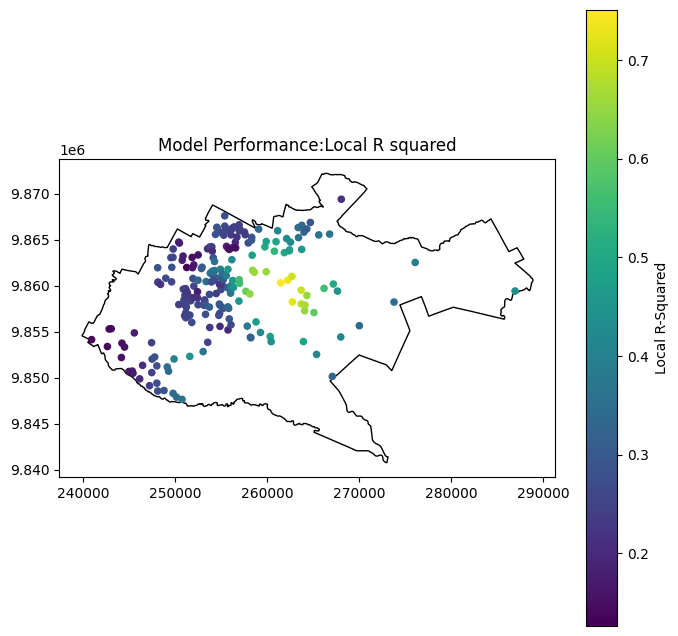

Mean Local R2: 0.321


In [ ]:
gwr_feature_space["local_R2"] = gwr_results.localR2

ax = boundary.plot(figsize=(8,8), edgecolor="black", facecolor="none")
gwr_feature_space.plot(
    ax=ax,
    column="local_R2",
    cmap="viridis",
    legend=True,
    markersize=20,
    legend_kwds={'label': "Local R-Squared"}
)
plt.title("Model Performance:Local R squared")
plt.show()

print(f"Mean Local R2: {gwr_feature_space['local_R2'].mean():.3f}")

Fit of  predicted versus observed values

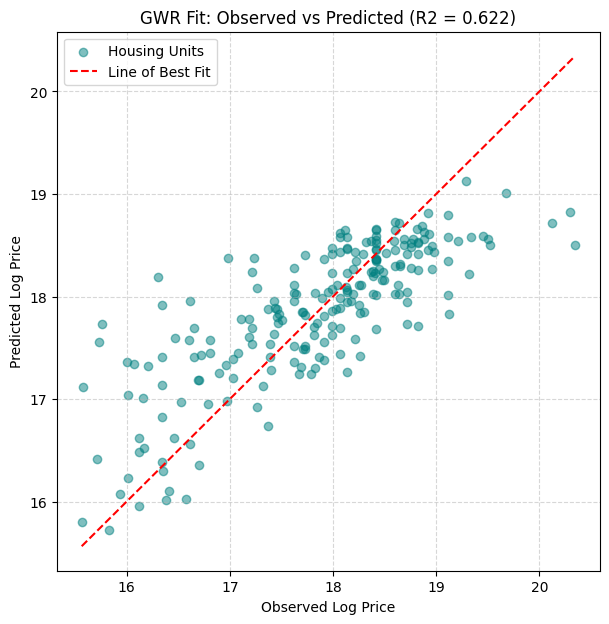

In [ ]:
from sklearn.metrics import r2_score

# Get predicted values
preds = gwr_results.predy.flatten()
actual = gwr_results.y.flatten()

# Calculate global R2 for the plot
global_r2 = r2_score(actual, preds)

plt.figure(figsize=(7,7))
plt.scatter(actual, preds, alpha=0.5, color="teal", label="Housing Units")

# Add perfect fit line
min_val = min(actual.min(), preds.min())
max_val = max(actual.max(), preds.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Line of Best Fit")

plt.xlabel("Observed Log Price")
plt.ylabel("Predicted Log Price")
plt.title(f"GWR Fit: Observed vs Predicted (R2 = {global_r2:.3f})")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()